# Quantum Exceptions

NicDeclic  
2026-11-12

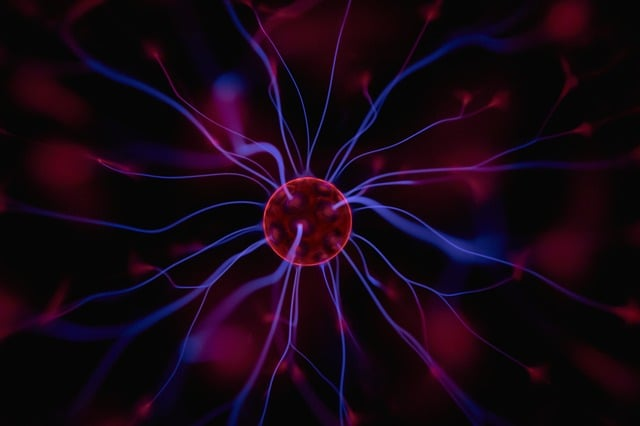

> *“Sometimes, constraints are the stars that guide.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

## When Boundary Conditions Break Chemistry

Take any logic gate in its molecular form—for instance, an AND gate
implemented via the **Barred Eight**—and inspect its allowed resonance
modes closely:

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Barred Eight")

# Add atoms
c2_1 = mol.add_atom(x=-0.7, y=1.0)
c2_2 = mol.add_atom(x=0.7, y=1.0)
c2_3 = mol.add_atom(x=-0.7, y=0)
c2_4 = mol.add_atom(x=0.7, y=0)
c2_5 = mol.add_atom(x=-0.7, y=-1.0)
c2_6 = mol.add_atom(x=0.7, y=-1.0)

# Add bonds
b2_1 = mol.add_bond(c2_1, c2_2, order="single")
b2_3 = mol.add_bond(c2_2, c2_5, order="single", label="C", label_pos=[0.25, 0.4])
b2_4 = mol.add_bond(c2_1, c2_3, order="single", label="A")
b2_5 = mol.add_bond(c2_2, c2_4, order="single")
b2_6 = mol.add_bond(c2_3, c2_4, order="single")
b2_7 = mol.add_bond(c2_3, c2_5, order="single")
b2_8 = mol.add_bond(c2_4, c2_6, order="single", label="B")
b2_9 = mol.add_bond(c2_5, c2_6, order="single")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>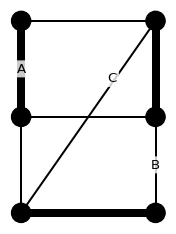</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>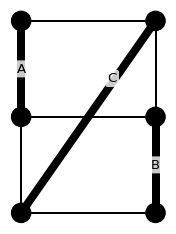</p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>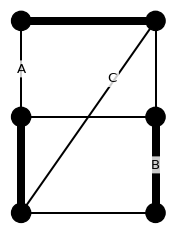</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>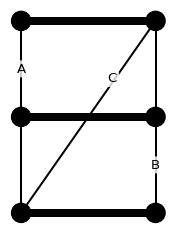</p>
</div></td>
</tr>
</tbody>
</table>

Notice a fundamental physical invariance: **every valid resonance
structure contains the same total number of single bonds (5) and double
bonds (3).**

This bond-count conservation is a strict thermodynamic prerequisite. It
ensures that all accessible resonance configurations reside at the exact
same ground-state energy level, allowing the delocalized
$\pi$-wavefunction to fluctuate freely across the network.

Now, what happens if we attempt to compute by posing a question that has
**no logically consistent physical answer**?

Suppose we take our molecular AND gate and clamp its boundary conditions
into an impossible contradiction:  
\* We hold input $A$ at state **“0”** (single bond).  
\* Simultaneously, we force the output $C$ to state **“1”** (double
bond).

In boolean logic, this is a direct contradiction: an AND gate can
*never* yield a 1 if an input is 0.

Even the flexible mathematics of quantum superpositions and transition
probabilities completely collapse here. There is simply **no valid
resonance mode** in the entire molecular manifold capable of bridging
this input to that output.

What actually happens to the physical carbon molecule if an
experimentalist stubbornly forces these incompatible boundary conditions
at both terminals?

Because the carbon skeleton cannot satisfy its strict local octet rule
(four covalent bonds per carbon) under these conditions, the network is
physically torn out of its neutral ground state: **the molecule is
forced into an ionized state.**

- A carbon vertex is stripped of an electron, creating a high-energy
  **carbocation** ($C^+$),  
- Or an uncompensated electron accumulates, creating a reactive
  **carbanion** ($C^-$).

This is what we define as a **Quantum Exception**.

Within the paradigm of Conjugated Carbon Computing (CCC), **ions and
free radicals are not native computational states—they are physical
signatures of unresolved logic.**

This is Nature’s way of saying “I don’t know”.

------------------------------------------------------------------------

### The Hardware Analogy: The Molecular Division by Zero

In classical microprocessors (such as x86 or ARM architectures),
attempting an illegal mathematical operation—such as dividing an integer
by zero—triggers a hardware interrupt: an **unhandled CPU exception**.
The processor halts the pipeline, raises an error flag, and branches to
an exception handler.

Ionization is the molecular hardware equivalent of a **division by
zero**:  
\* It is a catastrophic violation of boundary constraints.  
\* The computational energy diverges.  
\* The molecule halts its unitary calculation by paying an enormous
electrostatic penalty ($\approx 3\text{--}5\ \text{eV}$).

Far from being a defect of the theory, this reveals a beautiful physical
self-consistency: **the laws of thermodynamics act as the built-in
operating system of the molecule**, strictly enforcing logical
consistency under penalty of ionization!

------------------------------------------------------------------------

## Matrix Formulation: Testing for Molecular Ionization

There is a formal algebraic method to determine whether any arbitrary
carbon molecule can exist in a stable, neutral state or whether it is
fundamentally forced to become an ion.

The procedure is universal: we compose the entire molecule into its
global transition matrix.

Depending on the nature of the problem, specific boundary bonds can be
clamped to fixed values if desired, or left entirely free to resonate.

When evaluated as an isolated, closed system with zero free inputs and
zero free outputs, the resulting global transition matrix has dimensions
$2^0 \times 2^0$, which is simply a **single $1 \times 1$ scalar
matrix**:

Under our standard normalization operator $\{\dots\}$, this scalar
collapses into one of two decisive binary outcomes:

$$\{\mathbf{Molecule}\} = \begin{cases} 
\begin{bmatrix} 1 \end{bmatrix} & \implies \textbf{No Exception} \text{ (Neutral, Non-Ionized Molecule)} \\
\begin{bmatrix} 0 \end{bmatrix} & \implies \textbf{Quantum Exception} \text{ (Forced Ionized / Radical State)}
\end{cases}$$

- **If $\{\mathbf{Molecule}\} = [1]$:** The molecule possesses at least
  one valid, unfrustrated resonance mode where every carbon satisfies
  its four covalent bonds. The molecule can exist in a neutral ground
  state.  
- **If $\{\mathbf{Molecule}\} = [0]$:** It is mathematically impossible
  for the carbon skeleton to satisfy local valency rules. The molecule
  has zero valid neutral resonance states and **has no physical choice
  but to become an ion or a free radical.**

------------------------------------------------------------------------

### Demonstrating with Two Elementary Shapes

To visualize this distinction directly, consider two minimal carbon
rings evaluated as closed systems:

#### 1. The Square Ring (4 Carbons):

A 4-carbon conjugated loop possesses an even number of vertices.  
\* It accommodates two distinct resonance states:

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Square")

# Add atoms
c1 = mol.add_atom(x=-0.5, y=0.5)
c2 = mol.add_atom(x=0.5, y=0.5)
c3 = mol.add_atom(x=-0.5, y=-0.5)
c4 = mol.add_atom(x=0.5, y=-0.5)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c1, c3, order="single")
b3 = mol.add_bond(c2, c4, order="single")
b4 = mol.add_bond(c3, c4, order="single")

all_resonances = mol.resonance()

for i, res_mol in enumerate(all_resonances):
    res_mol.draw() 
```

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>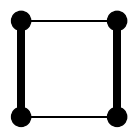</p>
</div></td>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>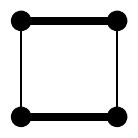</p>
</div></td>
</tr>
</tbody>
</table>

- Evaluating its closed transition matrix yields:

``` python
square = open @ (identity ^ identity) @ close

display_inline(r"\Big\{", "Square", r"\Big\}", "=", "Open", r"\cdot", "(Identity", r"\otimes", "Identity)", r"\cdot", "Close", "=", square)
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \Big\{ Square \Big\} = Open \cdot
(Identity \otimes Identity) \cdot Close =  \begin{array}{|c|}  \hline 1
\\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

- **Verdict:** Zero exception. The molecule is stable and neutral.

#### 2. The Triangular Ring (3 Carbons):

A 3-carbon loop possesses an odd number of vertices:

``` python
# Create a conjugated carbon molecule
mol = CarbonMolecule("Triangular")

# Add atoms
c1 = mol.add_atom(x=0.0, y=0.5, label="+")
c2 = mol.add_atom(x=-0.5, y=-0.5)
c3 = mol.add_atom(x=0.5, y=-0.5)

# Add bonds
b1 = mol.add_bond(c1, c2, order="single")
b2 = mol.add_bond(c2, c3, order="double")
b3 = mol.add_bond(c3, c1, order="single")

mol.draw() 
```

<table style="width:50%;">
<colgroup>
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%"
data-layout-align="center">
<p>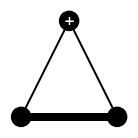</p>
</div></td>
</tr>
</tbody>
</table>

- By fundamental valency rules, it is impossible for three trivalent
  carbons in a closed ring to each hold exactly one double bond
  simultaneously without creating an uncompensated charge or an unpaired
  electron.  
- The internal resonance paths cancel out completely to zero:

``` python
triangular = open @ (identity ^ identity) @ terminate

display_inline(r"\Big\{", "Triangular", r"\Big\}", "=", "Open", r"\cdot", "(Identity", r"\otimes", "Identity)", r"\cdot", "Terminate", "=", triangular)
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \Big\{ Triangular \Big\} = Open \cdot
(Identity \otimes Identity) \cdot Terminate
=  \begin{array}{|c|}  \hline 0 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

- **Verdict: Quantum Exception!** The neutral molecule cannot exist. It
  is forced to become an ion (such as the cyclopropenyl cation
  $C_3H_3^+$) or a radical.

Of course, evaluating this matrix contraction is not magically free.

As the molecular graph expands, computing the global transition matrix
algebraically requires manipulating matrix dimensions that scale
exponentially. For large and sprawling molecular networks, this
classical matrix algebra rapidly becomes computationally demanding.

Nevertheless, at the conceptual and formal level, the algebraic
criterion remains absolute: if the normalized scalar evaluates to $[0]$,
nature raises an unhandled quantum exception—the problem remains
physically unresolved unless an external charge is introduced.

------------------------------------------------------------------------

## 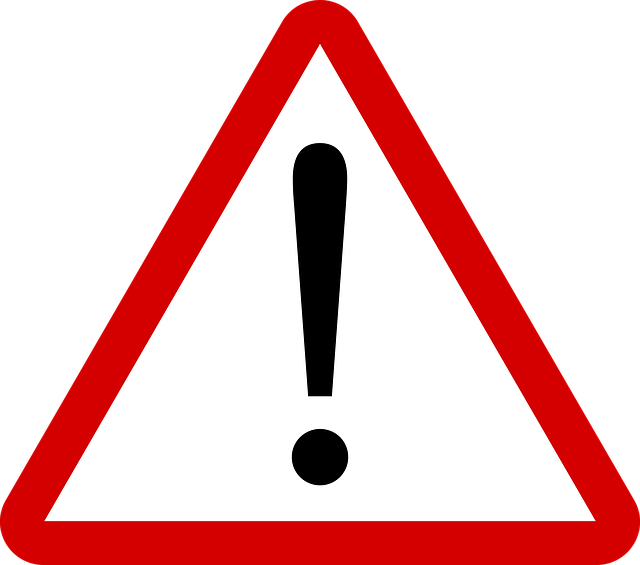 Speculations & Wild Thoughts

- Quantum Exceptions & The Tar Paradox

During a Quantum Exception, ionization does not occur uniformly or at
random.

Because the molecular topology dictates the energy landscape, the forced
ionic defects ($C^+$ carbocations or $C^-$ carbanions) localize at very
specific, predictable atomic coordinates across the carbon skeleton.

Furthermore, if we consider that molecules in a realistic environment
are continually subjected to fluctuating external conditions—effectively
receiving an ongoing stream of varied computational “problems” to
resolve—these localized charge displacements do not merely form static
spatial points: **they carve intricate, dynamic signatures across space
and time.**

Now, consider what happens when these molecules are granted physical
mobility—such as drifting freely within a prebiotic primordial ocean:

These spatiotemporal ionization patterns act as highly specific,
electro-topological “fingerprints.”. A molecule trapped in an
unresolvable state (a “problem molecule,” bearing a localized positive
exception) will naturally experience long-range Coulombic attraction
toward a complementary network (a “higher-level solution molecule,”
carrying a matching negative exception).

They do not collide blindly: **they are dynamically steered toward each
other by their mutual computational incompatibility.**

When these complementary topologies dock and react, their opposing
charges neutralize each other, resolving the exception and restoring
ground-state resonance across the newly merged macro-network. Such
highly selective, self-assembling reactions are fundamentally
**negentropic** (entropy-reducing)—locally extracting order and
structural coherence out of surrounding thermodynamic chaos.

Could this informational mechanism offer a missing chapter to the famous
**Miller-Urey experiment** (1952)?

In origin-of-life chemistry, researchers inevitably slam into what
astrobiologist Steven Benner coined the **“Tar Paradox” (the Asphalt
Wall)**:  
\* When organic molecules are exposed to unguided prebiotic energy
(spark discharges, UV radiation, heat), organic chemistry does not
spontaneously assemble into delicate RNA or proteins.  
\* Instead, it rapidly devolves into an intractable, brown-black,
biologically dead **sludge—synthetic tar.**

Perhaps prebiotic chemistry broke through the Tar Paradox not by pure
geochemical chance, but through **quantum computational selection**:

If conjugated carbon networks act as resonant filters, random
polymerization is suppressed. Only those molecular architectures whose
spatiotemporal exceptions find stable, resonance-closing partners
survive the evolutionary sieve.

Life did not begin by fighting thermodynamics in the dark. Life may have
begun as a self-correcting quantum error handler—navigating through the
primordial tar by pairing problems with their exact topological
solutions.

- Unresolved Wishes Across the Cosmos

The implications become even more enchanting when we look beyond direct
molecular contact:

An ionized carbon network trapped in a Quantum Exception does not have
to wait for a physical collision to relax. It can shed its excess
excitation energy by **emitting a photon**.

That photon—a solitary quantum of electromagnetic energy—can cross the
vast vacuum of space for millions, or even billions, of years, carrying
the exact energetic signature of the broken resonance, until it strikes
and ionizes another distant molecule across the cosmos.

Could radiative transfer be Nature’s long-range mechanism for balancing
its quantum accounting books—resolving exceptions across astronomical
scales?

Could we venture so far as to imagine that ions, photons, and cosmic
radiation are, at their deepest informational level, **a kind of
unresolved wish**? An unanswered question launched into the dark,
seeking an observer or a complementary structure capable of bringing it
to rest.

This poetic realization echoes our ancient childhood folklore: the
timeless instinct to **make a wish upon a shooting star**—a fleeting
streak of light born from cosmic dust burning as it seeks reconciliation
with the Earth.

Now, let your imagination scale up to the cosmos.

Picture a **black hole** lurking in deep space, quietly drinking in this
ancient radiation—gathering billions of years of stray photons,
collecting this tapestry of unresolved questions and unanswered wishes
emitted by dying stars and stressed matter across the eons.

Under certain speculative theories of cosmological natural selection,
the interior of a black hole does not lead to a dead singularity, but
blossoms outward into a Big Bang—**birthing a brand-new baby universe.**

What if that new cosmos is seeded and shaped by the very information
(wishes) it swallowed? A newborn universe endowed with new physical
constants, fresh matter, and an entirely blank canvas—ready to embark on
a whole new cycle of cosmic adventures!

Admittedly, this drifts far into the realm of wild, untamed speculation.

**But after all… what is science without the courage to dream?**

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“Quantum Set Theory”](../../posts/quantum-set-theory/index.html)**